# Q2. Are breeding declines concentrated in particular regions, habitats or ecological groups?

Map and zones use observed vs expected breeding records (each place keeps its own species mix). Groups use each species' breeding change from Q1. Traits are provisional (`species_traits_provisional.csv`).

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import kruskal
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
TRAITS_PATH = Path("species_traits_provisional.csv")
OUTPUT_DIR = Path("outputs")
PDF_NAME = "Q2_Decline_Concentration.pdf"

# Periods. 1977-1999 is the team's agreed early period. The agreed recent period (2000-2020) is split in two
# so we can see whether a decline is still going: 2000-2009 (Millennium Drought years) and 2010-2020 (after it).
PERIODS = {"E": (1977, 1999), "D1": (2000, 2009), "D2": (2010, 2020)}
MIN_EARLY_BREEDING = 30         # breeding records a species needs in 1977-1999
MIN_SIGHTINGS = 150             # sightings a species needs in each of 2000-2009 and 2010-2020
CELL_DEG = 0.5                  # map cell size (about 50 km)
MIN_EXPECTED = 10               # a map cell needs at least this many expected recent breeding records

ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
INTRODUCED = [948, 957, 989, 990, 991, 995, 996, 998, 999]
COLONIAL_WATERBIRDS = [96, 97, 99, 100, 101, 178, 179, 180, 181, 182, 185, 186, 187, 192, 977]  # nest in colonies
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
PLAB = {k: f"{a}–{b}" for k, (a, b) in PERIODS.items()}

In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)


DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}

In [3]:
logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)
PAGE_M = 0.7                                  # page margin, inches
ACCENT = BLUE

def _text(fig, y, s, size, weight="normal", color=INK, width=100, x=None, style="normal"):
    for line in textwrap.wrap(s, width=width):
        fig.text((x or PAGE_M) / A4[0], 1 - y / A4[1], line, fontsize=size, fontweight=weight, color=color, va="top",
                 fontstyle=style)
        y += size * 1.42 / 72
    return y

def _label(fig, y, s):
    fig.text(PAGE_M / A4[0], 1 - y / A4[1], s.upper(), fontsize=8.5, fontweight="bold", color=ACCENT, va="top")
    return y + 0.24

def _bullets(fig, y, items, marker_color=ACCENT, size=10, width=96, color=INK):
    for b in items:
        fig.text((PAGE_M + 0.02) / A4[0], 1 - (y - 0.01) / A4[1], "•", fontsize=size + 1, color=marker_color, va="top")
        y = _text(fig, y, b, size, width=width, x=PAGE_M + 0.22, color=color) + 0.07
    return y

def plain_page(pdf, label, title, chart, findings, causes, note, subtitle=None, chart_h=5.0):
    # White page with light typographic structure: label, title, chart, findings, speculation, note
    fig = plt.figure(figsize=A4)
    y = _label(fig, PAGE_M, label)
    y = _text(fig, y, title, 16, "bold", width=62)
    if subtitle:
        y = _text(fig, y + 0.04, subtitle, 11.5, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [1 - (y + 0.1) / A4[1]] * 2, color=GRID, lw=1))
    top = y + 0.2
    sub = fig.subfigures(3, 1, height_ratios=[top, chart_h, A4[1] - top - chart_h], hspace=0)[1]
    chart(sub)
    y = top + chart_h + 0.25
    y = _label(fig, y, "Key findings")
    y = _bullets(fig, y, findings) + 0.12
    y = _label(fig, y, "Possible causes  ·  our speculation, not tested here")
    y = _bullets(fig, y, causes, marker_color=MUTED, size=9.4, width=104, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [(PAGE_M + 0.42) / A4[1]] * 2, color=GRID, lw=0.8))
    _text(fig, A4[1] - PAGE_M - 0.32, note, 7.8, color=MUTED, width=140)
    pdf.savefig(fig); plt.close(fig)

def show_points(findings, causes):
    display(Markdown("**Key findings**\n" + "\n".join(f"* {p}" for p in findings) +
                     "\n\n**Possible causes (our speculation, not tested here)**\n" + "\n".join(f"* {c}" for c in causes)))

## Data and measure
**Breeding share:** of the Atlas surveys on which a species was recorded, the share with breeding evidence
(surveys only, as agreed). Each species is standardised to the same mix of months in every period, and compared
with the **typical species**, because breeding was recorded less often overall over time. DES (2021–2025) is not
pooled with the Atlas because it recorded breeding differently.

In [4]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "month",
        "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)    # grid codes are square centres
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"]
             & data["year"].between(PERIODS["E"][0], PERIODS["D2"][1])].copy()
edges = [PERIODS["E"][0] - 1] + [PERIODS[k][1] for k in ["E", "D1", "D2"]]
atlas["period"] = pd.cut(atlas["year"], edges, labels=["E", "D1", "D2"]).astype(str)
atlas["month"] = atlas["month"].astype(int)
atlas["zone"] = atlas["region"].astype(str).map(ZONES)
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
display(atlas.groupby("period").agg(surveys=("sheet_id", "nunique"), sightings=("breeding", "size"),
                                    breeding_share=("breeding", "mean")).reindex(["E", "D1", "D2"])
        .style.format({"surveys": "{:,.0f}", "sightings": "{:,.0f}", "breeding_share": "{:.2%}"}))

,surveys,sightings,breeding_share
period,,,
E,"131,152","3,171,770",3.56%
D1,"91,090","1,662,915",2.22%
D2,"23,304","693,158",2.01%


## Result

In [5]:
# Month-standardised breeding share for each species and period, using only months seen in all three periods
g = atlas.groupby(["species_id", "period", "month"])["breeding"].agg(["size", "sum"]).reset_index()
g = g.merge(atlas.groupby(["species_id", "month"]).size().rename("wt").reset_index(), on=["species_id", "month"])
g = g[g.groupby(["species_id", "month"])["period"].transform("nunique") == 3]
g["p"] = g["sum"] / g["size"]
g["wp"], g["wv"] = g["wt"] * g["p"], g["wt"] ** 2 * g["p"] * (1 - g["p"]) / g["size"]
agg = g.groupby(["species_id", "period"]).agg(wt=("wt", "sum"), wp=("wp", "sum"), wv=("wv", "sum"),
                                              n=("size", "sum"), b=("sum", "sum"))
agg["p"], agg["v"] = agg["wp"] / agg["wt"], agg["wv"] / agg["wt"] ** 2
r = agg[["p", "v", "n", "b"]].unstack("period")
r = r[(r["b"]["E"] >= MIN_EARLY_BREEDING) & (r["n"][["D1", "D2"]].min(axis=1) >= MIN_SIGHTINGS)]

sp = pd.DataFrame({"name": names.reindex(r.index)})
STEPS = {"step1": ("E", "D1"), "step2": ("D1", "D2"), "overall": ("E", "D2")}
TYPICAL = {}
for k, (a, b) in STEPS.items():
    ratio = r["p"][b] / r["p"][a]
    TYPICAL[k] = ratio.median()
    se = np.sqrt(r["v"][b] / r["p"][b] ** 2 + r["v"][a] / r["p"][a] ** 2)      # delta method, log scale
    rel = np.log(ratio / TYPICAL[k])
    sp[k], sp[k + "_lo"], sp[k + "_hi"] = np.exp(rel), np.exp(rel - 1.96 * se), np.exp(rel + 1.96 * se)
for per in ["E", "D1", "D2"]:
    sp[f"breeding_records_{per}"] = r["b"][per]
sp["introduced"] = sp.index.isin(INTRODUCED)

cont = (sp["step1"] < 1) & (sp["step2_hi"] < 1) & (sp["overall_hi"] < 1)
recovered = (sp["step1_hi"] < 1) & (sp["step2_lo"] > 1)
sp["trend"] = np.select(
    [cont, recovered, sp["step1_hi"] < 1, sp["step2_hi"] < 1, sp["overall_lo"] > 1],
    ["Continuing decline", "Fell, then recovered", "Fell, then steady", "New decline in 2010s", "Increasing"],
    "No clear change")
native = sp[~sp["introduced"]]
cont_sp = native[native["trend"] == "Continuing decline"].sort_values("overall")
counts = native["trend"].value_counts()

def observed_expected(df, key, a="E", b=None):
    """Recent breeding records observed vs expected if each species kept its earlier breeding share."""
    df = df if b is None else df[df["period"].isin([a, b])]
    lab = np.where(df["period"] == a, "a", "b")
    t = df.assign(_p=lab).groupby([key, "species_id", "_p"])["breeding"].agg(["size", "sum"]).unstack("_p").fillna(0)
    t = t[(t["size"]["a"] >= 10) & (t["size"]["b"] >= 10)]
    exp = (t["size"]["b"] * t["sum"]["a"] / t["size"]["a"]).groupby(level=0).sum()
    obs = t["sum"]["b"].groupby(level=0).sum()
    return pd.DataFrame({"obs": obs, "exp": exp, "oe": obs / exp})

# Map: early vs whole recent period (2000-2020), cells of CELL_DEG degrees
atlas["cell_lat"] = np.floor(atlas["lat"] / CELL_DEG) * CELL_DEG
atlas["cell_lon"] = np.floor(atlas["lon"] / CELL_DEG) * CELL_DEG
atlas["cell"] = list(zip(atlas["cell_lat"], atlas["cell_lon"]))
nsw = observed_expected(atlas.assign(all="NSW"), "all")["oe"].iloc[0]
cells = observed_expected(atlas, "cell")
cells = cells[cells["exp"] >= MIN_EXPECTED].copy()
cells["rel"] = cells["oe"] / nsw
BINS = [0, 0.5, 0.8, 1.25, 2, np.inf]
CLASS = ["much_less", "less", "typical", "more", "much_more"]
CLASS_LABEL = ["Faded a lot (under ½ NSW trend)", "Faded somewhat", "About NSW trend", "Held up better",
               "Held up much better (over 2×)"]
cells["cls"] = pd.cut(cells["rel"], BINS, labels=CLASS, right=False)
cells.reset_index().round(3).to_csv(OUTPUT_DIR / "Q2_breeding_map_cells.csv", index=False)

# Zones: each step relative to the NSW change in that step
zrows = []
for step, (a, b) in {"step1": ("E", "D1"), "step2": ("D1", "D2")}.items():
    st = observed_expected(atlas.assign(all="NSW"), "all", a, b)["oe"].iloc[0]
    z = observed_expected(atlas, "zone", a, b)
    for zone, row in z.iterrows():
        zrows.append(dict(zone=zone, step=step, rel=row["oe"] / st))
zones = pd.DataFrame(zrows).pivot(index="zone", columns="step", values="rel").reindex(ZONE_ORDER)
zones.round(3).to_csv(OUTPUT_DIR / "Q2_breeding_zones.csv")

# Groups: overall change (E -> D2) relative to typical, by trait
TRAITS = [("habitat", "Main habitat"), ("diet", "Main diet"), ("movement", "Movement")]
q = native.join(traits[[t for t, _ in TRAITS]], how="inner")
q["pct"] = (q["overall"] - 1) * 100
q["cont"] = q["trend"] == "Continuing decline"
rng = np.random.default_rng(2)
grp_rows, tests = [], {}
for t, label in TRAITS:
    groups = {k: v for k, v in q.groupby(t) if len(v) >= 6}
    tests[label] = kruskal(*[v["pct"] for v in groups.values()]).pvalue
    for k, v in groups.items():
        bs = [np.median(rng.choice(v["pct"].values, len(v))) for _ in range(2000)]
        grp_rows.append(dict(trait=label, group=k, n=len(v), median=v["pct"].median(), lo=np.percentile(bs, 2.5),
                             hi=np.percentile(bs, 97.5), n_cont=int(v["cont"].sum())))
grp = pd.DataFrame(grp_rows)
grp.round(2).to_csv(OUTPUT_DIR / "Q2_breeding_groups.csv", index=False)
display(zones.round(2)); display(grp.sort_values("median").round(1))
print(f"{len(cells)} map cells; trait tests p =", {k: round(v, 4) for k, v in tests.items()})

step,step1,step2
zone,,
Coast,1.13,1.02
Tablelands,1.02,0.82
Inland,0.82,1.06


,trait,group,n,median,lo,hi,n_cont
8,Main diet,Fruit,9,-26.8,-34.2,70.6,1
17,Movement,Summer migrant,34,-20.3,-32.7,23.4,4
9,Main diet,Insects,105,-17.7,-25.0,-1.4,6
7,Main diet,Fish & aquatic animals,23,-14.3,-70.8,11.0,4
6,Main habitat,Woodland,80,-12.9,-23.4,7.6,6
2,Main habitat,Grassland & open,38,-7.6,-35.6,26.1,2
15,Movement,Nomadic or part-migrant,65,-5.5,-35.4,8.9,6
3,Main habitat,Shrubland & heath,19,-0.1,-45.1,87.9,0
10,Main diet,Meat (vertebrates),19,1.8,-22.9,28.1,0
11,Main diet,Nectar,24,4.2,-25.5,43.7,1


222 map cells; trait tests p = {'Main habitat': np.float64(0.4987), 'Main diet': np.float64(0.0034), 'Movement': np.float64(0.0421)}


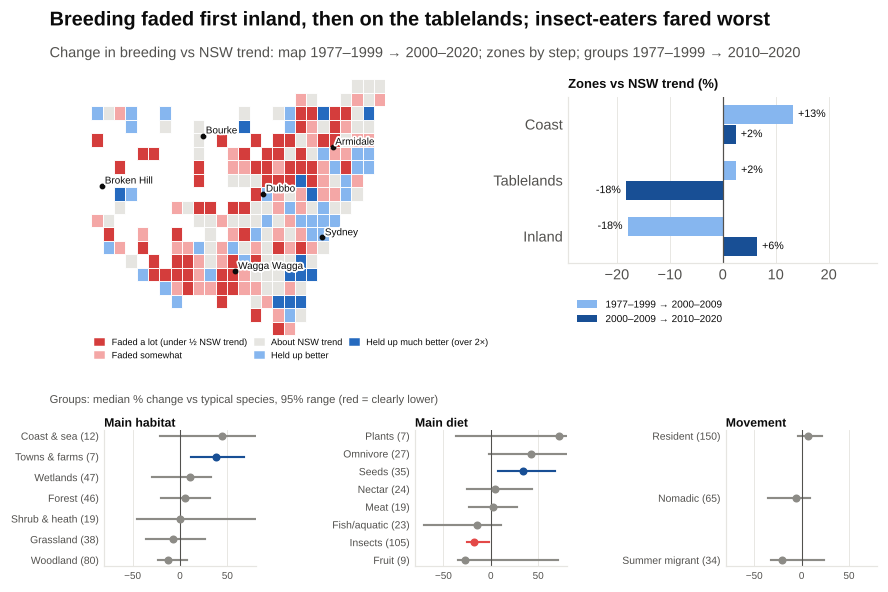

In [6]:
FRIENDLY = {"Insects": "insect-eaters", "Seeds": "seed-eaters", "Fruit": "fruit-eaters", "Woodland": "woodland birds",
            "Wetlands": "wetland birds", "Summer migrant": "summer migrants", "Grassland & open": "grassland birds",
            "Fish & aquatic animals": "fish- and water-feeders", "Nomadic or part-migrant": "nomads",
            "Omnivore": "omnivores", "Towns & farms": "birds of towns and farms"}
def where(z): return "inland" if z == "Inland" else f"on the {z.lower()}"
SHORT = {"Grassland & open": "Grassland", "Shrubland & heath": "Shrub & heath", "Fish & aquatic animals": "Fish/aquatic",
         "Meat (vertebrates)": "Meat", "Nomadic or part-migrant": "Nomadic", "Towns & farms": "Towns & farms"}

def chart_q2(fig):
    z1, z2 = zones["step1"].idxmin(), zones["step2"].idxmin()
    low = grp[grp["hi"] < 0].sort_values("median")
    tail = f"; {FRIENDLY.get(low['group'].iloc[0], low['group'].iloc[0].lower())} fared worst" if len(low) else ""
    headline(fig, f"Breeding faded first {where(z1)}, then {where(z2)}{tail}", f"Change in breeding vs NSW trend: map {PLAB['E']} → 2000–2020; zones by step; "
                                    f"groups {PLAB['E']} → {PLAB['D2']}")
    mx = fig.add_axes([0.0, 0.42, 0.55, 0.44])
    for _, r_ in cells.reset_index().iterrows():
        mx.add_patch(Rectangle((r_["cell"][1], r_["cell"][0]), CELL_DEG, CELL_DEG, facecolor=DIV[r_["cls"]],
                               edgecolor="white", lw=0.6))
    nsw_axes(mx)
    label_towns(mx, ["Sydney", "Dubbo", "Armidale", "Wagga Wagga", "Broken Hill", "Bourke"], size=6.5)
    mx.legend(handles=[Patch(color=DIV[c], label=l) for c, l in zip(CLASS, CLASS_LABEL)], loc="upper left",
              bbox_to_anchor=(0.0, 0.04), ncol=3, fontsize=6.0, handlelength=1.0, columnspacing=0.8)
    zx = fig.add_axes([0.64, 0.55, 0.34, 0.28])
    y = np.arange(len(ZONE_ORDER))[::-1]
    for j, (step, col, lab) in enumerate([("step1", LIGHT_BLUE, f"{PLAB['E']} → {PLAB['D1']}"),
                                          ("step2", DARK_BLUE, f"{PLAB['D1']} → {PLAB['D2']}")]):
        v = (zones[step] - 1) * 100
        zx.barh(y + (0.18 if j == 0 else -0.18), v, height=0.34, color=col, label=lab)
        for yi, val in zip(y, v):
            zx.text(val + (1 if val >= 0 else -1), yi + (0.18 if j == 0 else -0.18), f"{val:+.0f}%", fontsize=7,
                    va="center", ha="left" if val >= 0 else "right")
    zx.axvline(0, color=INK2, lw=0.8); zx.set_yticks(y, ZONE_ORDER); zx.grid(axis="y", visible=False)
    lim = max(abs((zones - 1) * 100).max().max() * 1.6, 10)
    zx.set_xlim(-lim, lim)
    zx.set_title("Zones vs NSW trend (%)", loc="left", fontsize=8.5, fontweight="bold")
    zx.legend(fontsize=6.6, loc="lower left", bbox_to_anchor=(0, -0.42), ncol=1)
    gx = fig.add_gridspec(1, len(TRAITS), left=0.13, right=0.98, top=0.27, bottom=0.04, wspace=1.05).subplots()
    for ax, (t, label) in zip(gx, TRAITS):
        g = grp[grp["trait"] == label].sort_values("median")
        yy = np.arange(len(g))
        for yi, (_, r_) in zip(yy, g.iterrows()):
            col = RED if r_["hi"] < 0 else (DARK_BLUE if r_["lo"] > 0 else MUTED)
            ax.plot([max(r_["lo"], -80), min(r_["hi"], 80)], [yi, yi], color=col, lw=1.4)
            ax.scatter(r_["median"], yi, s=18, color=col, zorder=3)
        ax.set_yticks(yy, [f"{SHORT.get(k, k)} ({n})" for k, n in zip(g["group"], g["n"])], fontsize=6.8)
        ax.axvline(0, color=INK2, lw=0.7); ax.set_xlim(-80, 80); ax.grid(axis="y", visible=False)
        ax.tick_params(axis="x", labelsize=6.5)
        ax.set_title(label, loc="left", fontsize=8, fontweight="bold", pad=2)
    fig.text(0.07, 0.315, "Groups: median % change vs typical species, 95% range (red = clearly lower)",
             fontsize=7.4, color=INK2)

show(chart_q2, "Q2_breeding_concentration")

In [7]:
lows = grp[grp["hi"] < 0].sort_values("median")
REASON = {"Wetlands": "less flooding reaching wetlands (river regulation and extraction) and fewer visits to colonies",
          "Fish & aquatic animals": "the same wetland pressures, since these feed in flooded wetlands",
          "Woodland": "ageing, isolated remnant trees and loss of shrub layer for nesting",
          "Insects": "fewer insects where grazing, pesticides and drought thin the ground layer",
          "Summer migrant": "pressures on migration routes and wintering grounds as well as in NSW",
          "Grassland & open": "pasture improvement, cropping and heavy grazing of nesting cover",
          "Nomadic or part-migrant": "fewer of the boom years that nomads need to breed"}
cell_zone = atlas.drop_duplicates("cell").set_index("cell")["zone"]
faded_by_zone = cells.assign(zone=cell_zone.reindex(cells.index).values, faded=cells["cls"].isin(["much_less", "less"])
                             ).groupby("zone")["faded"].mean().reindex(ZONE_ORDER) * 100
z1, z2 = zones["step1"].idxmin(), zones["step2"].idxmin()
Q2_POINTS = [
    f"Breeding fell most {where(z1)} from {PLAB['E']} to {PLAB['D1']} ({(zones.loc[z1, 'step1'] - 1) * 100:+.0f}% vs "
    f"NSW), then most {where(z2)} to {PLAB['D2']} ({(zones.loc[z2, 'step2'] - 1) * 100:+.0f}%).",
    "Map cells fading faster than NSW: " + ", ".join(f"{faded_by_zone[z]:.0f}% {z.lower()}" for z in ZONE_ORDER[::-1])
    + f" ({len(cells)} cells).",
    ("Clearly below typical: " + ", ".join(f"{FRIENDLY.get(k, k.lower())} ({m:+.0f}%)" for k, m in
                                           zip(lows["group"], lows["median"]))
     + ". Habitat groups do not differ by more than chance." if len(lows) else
     "No habitat, diet or movement group is clearly below typical."),
]
Q2_CAUSES = [
    (f"Inland breeding dropped in the Millennium Drought decade and recovered after "
     f"({(zones.loc['Inland', 'step2'] - 1) * 100:+.0f}% vs NSW): this fits drought, not lasting loss. The team's "
     f"rainfall analysis can test it." if zones.loc["Inland", "step2"] > 1 else
     "Inland breeding kept falling after the drought, pointing to lasting pressures such as clearing or grazing."),
    ("Tablelands kept falling after 2010, before the 2017–19 drought: a slow pressure such as dying paddock trees "
     "and dieback fits better than one drought." if zones.loc["Tablelands", "step2"] < 1 else
     "Tablelands breeding held up after 2010."),
    ("; ".join(f"{FRIENDLY.get(k, k).capitalize()} may be hit by {REASON[k]}" for k in lows["group"] if k in REASON) + "."
     if len(lows) and any(k in REASON for k in lows["group"]) else
     "No group stands out, so pressures may act on many kinds of birds at once."),
]
Q2_NOTE = (f"Map: {PLAB['E']} vs 2000–2020 (team periods), {CELL_DEG}° cells with at least {MIN_EXPECTED} expected "
           f"breeding records, species mix held fixed. The earlier version had 41 larger cells because it needed the "
           f"same squares surveyed in three periods.")
show_points(Q2_POINTS, Q2_CAUSES)

**Key findings**
* Breeding fell most inland from 1977–1999 to 2000–2009 (-18% vs NSW), then most on the tablelands to 2010–2020 (-18%).
* Map cells fading faster than NSW: 59% inland, 49% tablelands, 18% coast (222 cells).
* Clearly below typical: insect-eaters (-18%). Habitat groups do not differ by more than chance.

**Possible causes (our speculation, not tested here)**
* Inland breeding dropped in the Millennium Drought decade and recovered after (+6% vs NSW): this fits drought, not lasting loss. The team's rainfall analysis can test it.
* Tablelands kept falling after 2010, before the 2017–19 drought: a slow pressure such as dying paddock trees and dieback fits better than one drought.
* Insect-eaters may be hit by fewer insects where grazing, pesticides and drought thin the ground layer.

## PDF

In [8]:
with PdfPages(OUTPUT_DIR / PDF_NAME) as pdf:
    plain_page(pdf, "Question 2", "Are breeding declines concentrated in particular regions, habitats or "
               "ecological groups?", chart_q2, Q2_POINTS, Q2_CAUSES, Q2_NOTE, chart_h=5.3)
    pdf.infodict()["Title"] = "Are breeding declines concentrated?"
print("PDF written to", (OUTPUT_DIR / PDF_NAME).resolve())

PDF written to /home/user/birdbreed/decline_patterns/outputs/Q2_Decline_Concentration.pdf
